In [ ]:
!pip install egttools

In [ ]:
import os

import numpy as np
import matplotlib.pyplot as plt
import egttools as egt
import itertools
from egttools.analytical.utils import (calculate_gradients, find_roots, check_replicator_stability_pairwise_games, StochDynamics)
%matplotlib inline





We first define the matrix used for the computation of the results. We employ a function that generates this matrix for different values of $T$.

The function utilizes a dictionary to construct the base matrix, with values derived from the article. Specifically, for this analysis, we evaluate the Stag Hunt (SH) dilemma.

Additionally, we use a function to generate all possible combinations of signals. For example, if $\sigma = 2$, there are $2 \times 2^{\sigma}$ strategy pairs, meaning the set of strategies can be represented as $\{1CD, 1DC, \dots\}$.

To solve this problem, we utilize the \texttt{itertools} library. By providing the available moves and the exact number of signals, it returns all possible strategies corresponding to the signals.

In [ ]:
def payoff_matrix(T, num_signal):

    # Before we need to define the parameters and the base matrix
    R = 1; P = 0; S = -T
    base_payoffs = {'C': {'C': R, 'D': S}, 'D': {'C': T, 'D': P}}

    signals = [str(i) for i in range(num_signal)]
    moves = ['D', 'C'] # set of all actions can be use by agent

    strategy_labels = []
    strategies = {}

    reaction_funcs = list(itertools.product(moves, repeat=num_signal))


    # Here with this two loops we are defining exactly the matrix that is use
    # for the analysis


    # With this first two for we are going to define action sended and their
    # reactions as dictionary

    for signal_to_send in signals:

        for reaction_func in reaction_funcs:

            # Create a string label for it, e.g., "DCD"
            reaction_str = "".join(reaction_func)

            # We need to define the labels that is uses for the plot
            label = f"{signal_to_send}{reaction_str}"
            strategy_labels.append(label)

            # zip is a util function that set any value inside the signals
            # to the corresponding action inside the reaction_func
            react_dict = {s: m for s, m in zip(signals, reaction_func)}

            strategies[label] = {'signal': signal_to_send, 'react': react_dict}

    n_s = len(strategy_labels)


    # Now we have need to calculate the payoff matrix that is use for computing
    # everything

    # 4. Calculate the n_s x n_s payoff matrix
    A = np.zeros((n_s, n_s))
    for i in range(n_s):
        for j in range(n_s):
            # Get strategy i (player A) and strategy j (player B)
            strat_A = strategies[strategy_labels[i]]
            strat_B = strategies[strategy_labels[j]]

            # Find out what move they make against each other
            # Player A sees B's signal and reacts
            move_A = strat_A['react'][strat_B['signal']]
            # Player B sees A's signal and reacts
            move_B = strat_B['react'][strat_A['signal']]

            # Get the payoff for player A
            A[i, j] = base_payoffs[move_A][move_B]

    return A, n_s, strategy_labels, strategies



We now define the function used to compute the results. This step is necessary to evaluate the system across different values of $\beta$.

The implementation follows the same methodology described in the previous exercise.

The primary results of interest are the **stationary distribution** and the **fixation probabilities**. Specifically, the stationary distribution is used to plot the frequency of each strategy, while the fixation probabilities are used to generate the **invasion diagram**—a specialized plot that illustrates the transitions between monomorphic states.

In [ ]:
def calculate_stationary_distr(beta, game):
  Z= 150; beta=beta
  evolver = egt.analytical.PairwiseComparison(Z, game)

  transition_matrix, fixation_probabilities = evolver.calculate_transition_and_fixation_matrix_sml(beta)
  stationary_distribution = egt.utils.calculate_stationary_distribution(transition_matrix.transpose())
  return stationary_distribution, fixation_probabilities


The following function computes the average fraction of time spent in monomorphic cooperative states as a function of the Temptation to defect (T).

In [ ]:

def total_distr(strategies, strategy_labels, stationary_distribution):
  accum_stat_distr = 0


  # Now we need to define a simple lambda function that has used to establish how stationary distribution refer to cooperant strategy and which not
  delta = lambda x: 1 if x == 'C' else 0

  for i, label in enumerate(strategy_labels):

    # Get the correct strategy from the dictionary using the label
    stat = strategies[label]
    react_sig = stat['react'][label[0]]

    # Get the corresponding probability
    prob = stationary_distribution[i]

    # Add to total (will be prob * 1 or prob * 0)
    accum_stat_distr += prob * delta(react_sig)

  return accum_stat_distr

For the initial plots, we utilized a simplified approach rather than employing the custom function defined previously. This decision was made to avoid the overhead of creating additional wrapper functions, as the standard plotting commands are sufficiently simple and direct for these specific visualizations.

In [ ]:
A, n_s, strategy_labels, strategies = payoff_matrix(T=0.5, num_signal=2)

n_strategies = n_s
Z= 150;

# then we use the definition of the game

game = egt.games.Matrix2PlayerGameHolder(n_strategies, A)

In [ ]:

# Now we are going to compute the stationary distribution and his fixation probabilities

stationary_distribution, fixation_probabilities = calculate_stationary_distr(0.05, game)
print(stationary_distribution)

[0.08082186 0.01914399 0.27534331 0.12469084 0.08082186 0.27534331
 0.01914399 0.12469084]


The first plot represents the stationary distribution with 2 signals. As noted in the paper, these distributions are symmetric.

In [ ]:
count1 = count2 = 0

for i in range(len(stationary_distribution)):
    if i < len(stationary_distribution) / 2:
      count1 += stationary_distribution[i]
    else:
      count2 += stationary_distribution[i]

print(count1)
print(count2)

stationary_signal = []
stationary_signal.append(count1)
stationary_signal.append(count2)

0.4999999999999401
0.5000000000000601


(0.0, 1.0)

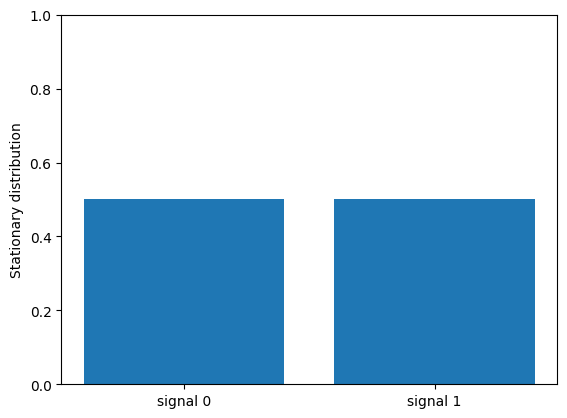

In [ ]:



fig, ax = plt.subplots()
ax.bar(['signal 0', 'signal 1'], stationary_signal)

ax.set_ylabel('Stationary distribution')
ax.set_ylim(0, 1)



(0.0, 0.3)

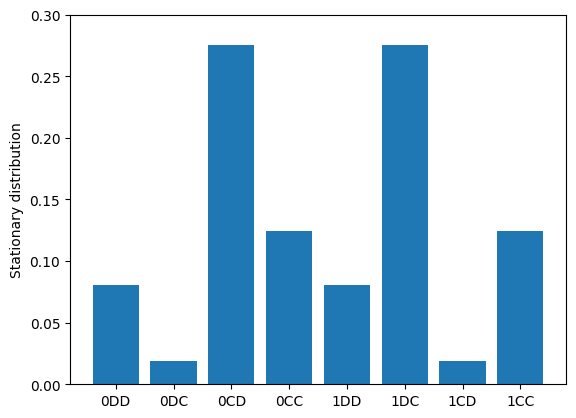

In [ ]:

# plot phase

fig, ax = plt.subplots()
ax.bar(strategy_labels, stationary_distribution)

ax.set_ylabel('Stationary distribution')
ax.set_ylim(0.0, 0.3)

(0.0, 1.0)

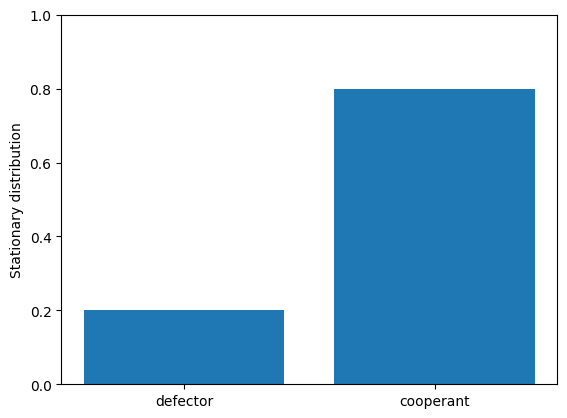

In [ ]:

# plot phase

total_react_0 = total_distr(strategies, strategy_labels, stationary_distribution)
fig, ax = plt.subplots()
ax.bar(['defector', 'cooperant'], [1-total_react_0, total_react_0] )

ax.set_ylabel('Stationary distribution')
ax.set_ylim(0, 1)


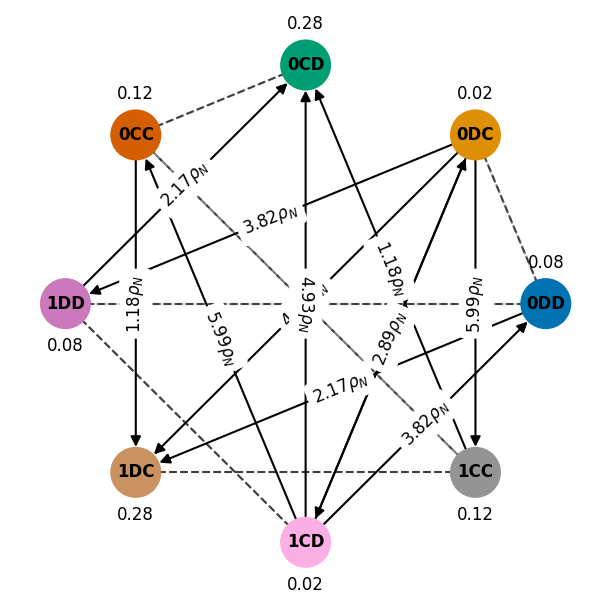

In [ ]:
#
# This is the invasion diagram, so the all of possibles monomorphic states and relatives fixation probabilities between them
#

fig, ax = plt.subplots(figsize=(5, 5), dpi=150)
G = egt.plotting.draw_invasion_diagram(strategy_labels,
                                              1/Z, fixation_probabilities, stationary_distribution,
                                              node_size=600,
                                              font_size_node_labels=8,
                                              font_size_edge_labels=8,
                                              font_size_sd_labels=8,
                                              edge_width=1,
                                              min_strategy_frequency=0.00001,
                                              ax=ax)
plt.axis('off')
plt.show() # display

We now describe the evolution of the population as the value of T in the matrix varies over time, while keeping β fixed.

This analysis is conducted specifically for the case of 3 signals.

In [ ]:

from tqdm import tqdm
epss=np.linspace(0, 1, 20)
num_signals = 3
beta = 0.05
avg = [ [] for _ in range(num_signals)]



for sigma in tqdm(range(1, num_signals + 1), desc="Signal Scenarios"):
  for t in epss:
    A, n_s, strategy_labels, strategies = payoff_matrix(T=t, num_signal=sigma)
    game = egt.games.Matrix2PlayerGameHolder(n_s, A)
    stationary_distribution, fixation_probabilities = calculate_stationary_distr(beta, game)
    total = total_distr(strategies, strategy_labels, stationary_distribution)

    avg[sigma-1].append(total)





Signal Scenarios: 100%|██████████| 3/3 [01:11<00:00, 23.97s/it]


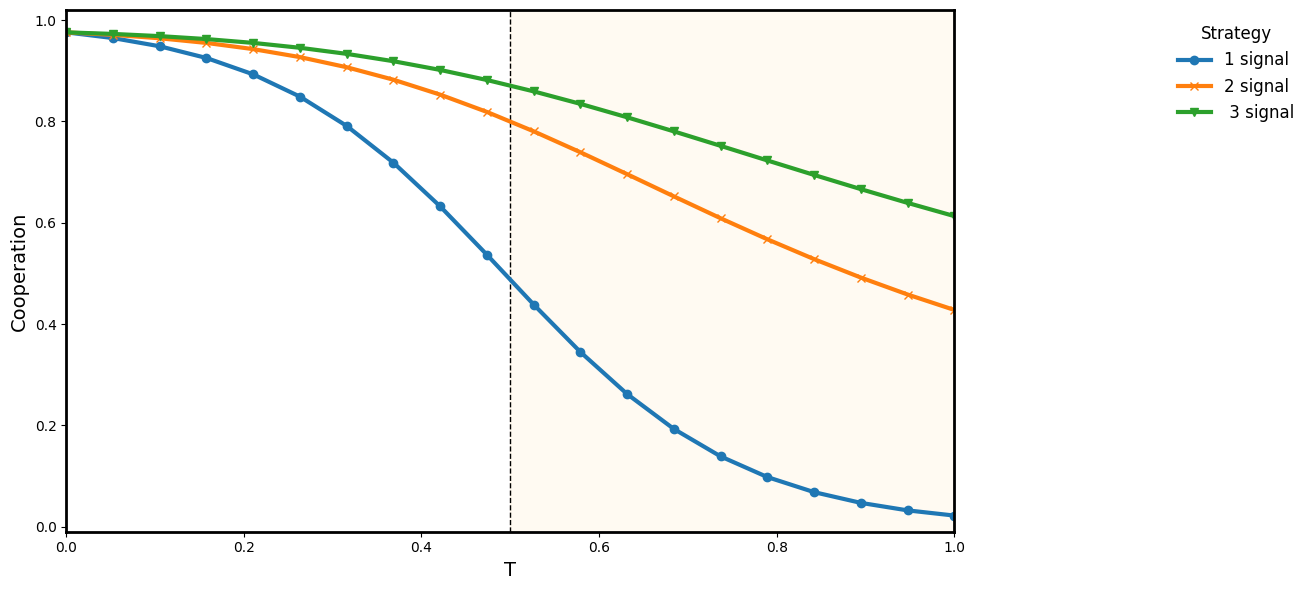

In [ ]:
import pandas as pd
import seaborn as sns


labels = ['1 signal', '2 signal', ' 3 signal']
markers = ['o', 'x', 'v', '^', 'X', '*', 'h', '1']
#colors=colors = sns.color_palette("icefire", 8)

fig, ax = plt.subplots(figsize=(14, 6))
ax.axvline(x=0.5, color='k', linestyle='--', linewidth=1)
ax.axvspan(xmin=0.5, xmax=1.0, color='orange', alpha=0.05)

for i in range(3):
    ax.plot(epss, avg[i],linewidth=3, label=labels[i], marker=markers[i])

border_width = 2.0
ax.spines['top'].set_linewidth(border_width)
ax.spines['right'].set_linewidth(border_width)
ax.spines['bottom'].set_linewidth(border_width)
ax.spines['left'].set_linewidth(border_width)
ax = plt.gca()
ax.set_ylim(-0.01, 1.02)
ax.set_ylabel('Cooperation', fontsize=14)
ax.set_xlabel('T', fontsize=14)
ax.set_xlim(0, 1)
plt.legend(title="Strategy", loc='upper right', bbox_to_anchor=(1.4, 1), frameon=False, fontsize=12,
          title_fontsize=12)




plt.tight_layout()
plt.show()

## Analysis where $\beta = 0.1$

With this value of $\beta$, the system exhibits worse performance than the reference case where $\beta=0.05$. Specifically, while cooperation was previously robust for $T \in [0.1,0.5]$, it now shows a clear decline.

This occurs because $\beta$ acts as the inverse of 'noise' in the decision-making process. When we use a lower $\beta$, we are effectively introducing more stochasticity (randomness) into the update rule. As $\beta \to 0$, the payoff differences become irrelevant, and the system behaves like random drift. Therefore, our lower parameter ($\beta=0.05$) clouds the evolutionary advantage of cooperators, making it harder for them to dominate the population despite their higher fitness.







## Critical overview of the paper


Based on this analysis, we conclude that pre-play signaling fundamentally alters evolutionary dynamics to favor cooperation.

A crucial factor in this process is the volume of signals: as the number of available signals increases, the tendency to cooperate rises significantly.

The mechanism for this cooperation differs between the two social dilemmas:



*   In the Stag Hunt (SH): The system reaches a stable state ($ESS_{N}$). Specifically, strategies that discriminate and cooperate with their own signal become the only stable strategies , ensuring high levels of stability for cooperation.
*   In the Prisoner's Dilemma (PD): There is no single monomorphic stable state ($ESS_{N}$​) for either cooperation or defection.
     However, this instability favors cooperation. Defection is no longer stable , and cooperation thrives through a dynamic "arms race" where cooperators use a diverse portfolio of signals to avoid deception.

    


Therefore, while the SH leads to a stable cooperative decision, the PD leads to a dynamic prevalence of cooperation, where cooperators succeed by constantly leveraging the complexity of the signaling system.

A critical constraint maintained by the model is the assumption of the Small Mutation Limit, where the mutation rate is assumed to be extremely rare ($\mu \to 0$).
Because mutations are so rare, the evolutionary process has enough time to reach a final state (either fixation or extinction of the mutant) before a new mutation occurs.
As a result, the population remains effectively monomorphic, meaning that at any given time, the population is composed almost entirely of individuals using the same strategy.
Therefore, a significant limitation of this analysis is that it cannot replicate the reality of polymorphic populations. Because the model restricts interactions to a 'one-vs-one' scenario (Resident vs. Mutant), we cannot verify how the dynamics would change if multiple conflicting strategies were competing simultaneously.

---


## I will declare that I used an LLM for coding assistance, as I am unfamiliar with programming in NumPy and plotting graphics with the matplotlib library, and to correct syntax and grammar errors in my written report.


---